<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan1/BTVN/MachineLearningT1_BTVN_Bai3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc du lieu: (506, 13)
5 dong dau:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   

   PTRATIO       B  LSTAT  
0     15.3  396.90   4.98  
1     17.8  396.90   9.14  
2     17.8  392.83   4.03  
3     18.7  394.63   2.94  
4     18.7  396.90   5.33  
So gia tri thieu: 0
So mau huan luyen: 404
So mau kiem tra: 102
MSE: 24.2911
R2: 0.6688


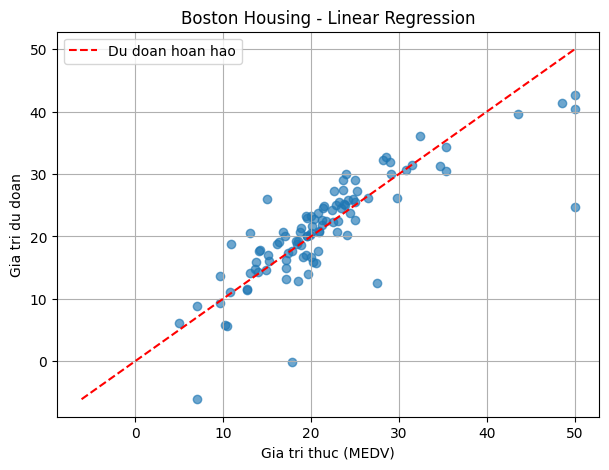

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tai du lieu Boston Housing tu OpenML
boston = fetch_openml(data_id=531, as_frame=True)
X = boston.data.copy()
y = pd.to_numeric(boston.target, errors="coerce")

# 2. Kiem tra du lieu
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("Kich thuoc du lieu:", X.shape)
print("5 dong dau:")
print(X.head())
print("So gia tri thieu:", X.isna().sum().sum() + y.isna().sum())

# Loai bo dong bi thieu neu co
data = X.copy()
data["MEDV"] = y.to_numpy()
data = data.dropna()

X = data.drop(columns=["MEDV"])
y = data["MEDV"]

# 3. Chia 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Huan luyen Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Du doan
y_pred = model.predict(X_test)

# 6. Danh gia
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("So mau huan luyen:", len(X_train))
print("So mau kiem tra:", len(X_test))
print("MSE:", round(mse, 4))
print("R2:", round(r2, 4))

# 7. Ve bieu do so sanh
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.65)

min_v = min(y_test.min(), y_pred.min())
max_v = max(y_test.max(), y_pred.max())

plt.plot([min_v, max_v], [min_v, max_v],
         color="red", linestyle="--",
         label="Du doan hoan hao")

plt.xlabel("Gia tri thuc (MEDV)")
plt.ylabel("Gia tri du doan")
plt.title("Boston Housing - Linear Regression")
plt.legend()
plt.grid(True)
plt.show()
